In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np


print("PyTorch :", torch.__version__)

device = torch.device("mps" if torch.mps.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.14.1
Device : mps


# **1. Jeu de données MNIST**

MNIST contient des images de chiffres manuscrits de taille :

28 x 28 = 784

Chaque image possède un label entre 0 et 9.

Nous utiliserons le **même dataset** pour comparer plusieurs paradigmes d'apprentissage.

In [57]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data",
                               train = True,
                               download = True,
                               transform = transform)

test_dataset = datasets.MNIST(root="./data",
                              train = False,
                              download = True,
                              transform = transform)

train_loader = DataLoader(dataset = train_dataset, batch_size = 128, shuffle = True)
test_loader = DataLoader(dataset = test_dataset, batch_size = 128, shuffle = False)



print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


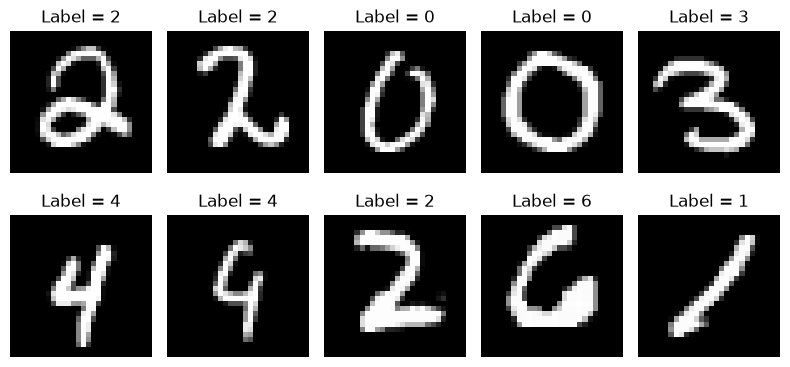

In [58]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# **Partie I — Modèle discriminatif**

# **2. Classification : apprendre \(P(y|x)\)**

Un classifieur reçoit une entrée \(x\) et prédit une classe \(y\).
$$
\
x \longrightarrow \text{Réseau de neurones} \longrightarrow \hat y
\
$$
L'objectif est d'apprendre approximativement :
$$
\
P(y|x)
\
$$
Nous allons utiliser un réseau entièrement connecté simple.

In [59]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784,128),
            nn.ReLU(),
            nn.Linear(128,10),
        )
    def forward(self,x):
        return self.net(x)
classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [60]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr= 1e-3)

In [61]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4122
Epoch 2/3 - Loss = 0.1950
Epoch 3/3 - Loss = 0.1420


In [62]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.12%


In [63]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

Accuracy = 96.12%


# **Partie II — Autoencodeur**

# **3. Idée générale**

Un autoencodeur apprend à reconstruire son entrée :

x \rightarrow Encoder \rightarrow z \rightarrow Decoder \rightarrow \hat x
 x -> Encoder -> z -> Decoder -> xhat

avec : xhat approxime x


Le vecteur z est une **représentation latente** de l'entrée.

L'apprentissage devient : x -> x

Les labels ne sont plus nécessaires.

In [64]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),  
            nn.Linear(128, 784),
            nn.Sigmoid(),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        x_hat = x_hat.view(-1, 1, 28, 28)
        return x_hat


ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [65]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0654
Epoch 2/5 - Loss = 0.0527
Epoch 3/5 - Loss = 0.0505
Epoch 4/5 - Loss = 0.0485
Epoch 5/5 - Loss = 0.0463


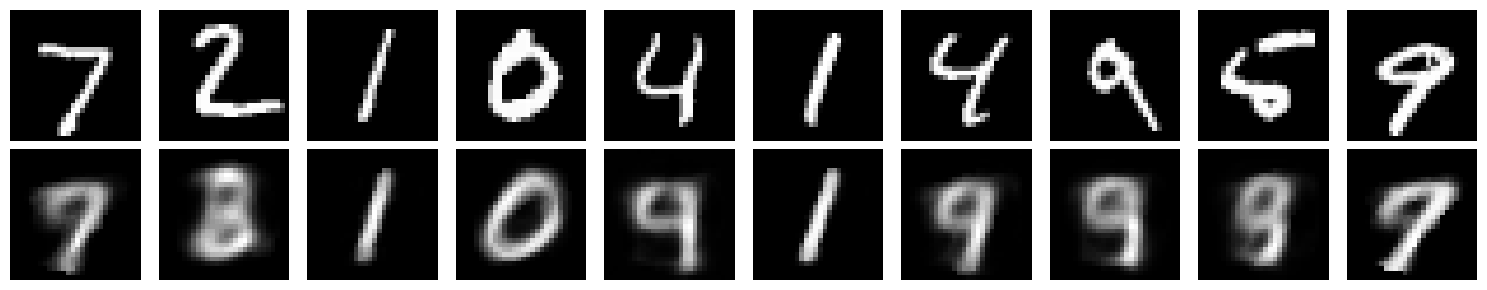

In [66]:
ae.eval()

x, _ = next(iter(test_loader))
x= x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show() 

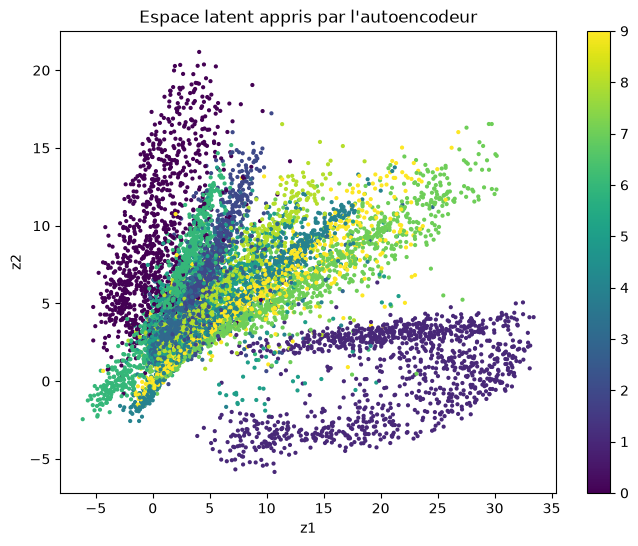

In [67]:
ae.eval()

zs= []
ys = []

with torch.no_grad():
    for x,y in test_loader:
        x = x.to(device)
        z = ae.encoder(x)
        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()



Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()


In [80]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        images = images[labels == chiffre]

        if len(images) == 0:
            continue

        z = model.encoder(images.to(device))

        somme_z = z.sum(dim=0, keepdim=True) if somme_z is None else somme_z + z.sum(dim=0, keepdim=True)
        nombre += len(images)

    z_moyen = somme_z / nombre

    image = model.decoder(z_moyen).view(-1, 1, 28, 28)
    return image.cpu()

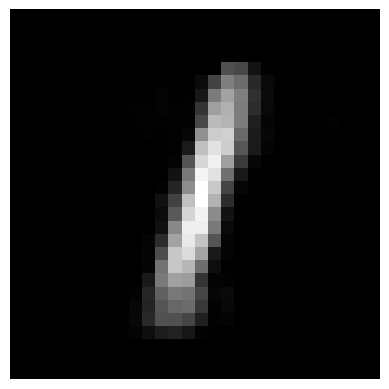

In [82]:
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.axis("off")
plt.show()

# **Partie III — Variational Autoencoder (VAE)**

# **8. Principe**

Au lieu d'associer une entrée \(x\) à un point latent unique, le VAE associe \(x\) à une distribution :
$$
\
q(z|x)=\mathcal{N}(\mu,\sigma^2)
\
$$
L'encodeur produit :
$$
\
\mu(x)
\
$$
et :
$$
\
\log \sigma^2(x)
\
$$
Puis nous échantillonnons \(z\).